<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/HybridQNN_CANAttack_Islam2021.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical neural network for in-vehicle (CAN bus) attack detection: Islam et al. (2021) step by step

This notebook re-implements, runs and checks the method of

> Mhafuzul Islam, Mashrur Chowdhury, Zadid Khan and Sakib Mahmud Khan,
> "Hybrid Quantum-Classical Neural Network for Cloud-supported In-Vehicle Cyberattack Detection",
> IEEE Sensors Letters, 2021 (arXiv:2110.07467). https://arxiv.org/abs/2110.07467

The paper ran **TensorFlow Quantum + Cirq**, which cannot be installed on a normal Colab runtime any more. The paper's quantum
network is a small, well-defined circuit (the Farhi-Neven classifier of the TensorFlow Quantum MNIST tutorial), so we rebuild
it **gate for gate in PennyLane** and train it with **PyTorch**. Everything else (CAN decoding, the amplitude-shift attack,
the CAN images, the CNN, the LSTM baseline) is written from the paper's description.

**What the notebook does.**
1. Downloads the public HCRL *OTIDS* attack-free CAN log recorded from a **KIA Soul** (the data the paper used) and decodes
   it into the paper's 13 vehicle signals with the OpenDBC `hyundai_kia_generic.dbc` file.
2. Injects the paper's **amplitude-shift attack** (Table II), builds **13 x 13 CAN images**, and trains three detectors:
   the **hybrid** CNN + 17-qubit quantum network, the **quantum-only** network and an **LSTM**; plus Random-Forest and
   RBF-SVM baselines on identical inputs.
3. Re-draws the paper's Fig. 3 and Fig. 4, and ends with a claim-by-claim verdict against the paper's numbers.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
PennyLane (PyTorch is preinstalled on Colab). No GPU and no quantum-cloud account are needed.

**Runtime.** `FAST_MODE = True` (about 1,200 training images, 1 quantum epoch) takes a few minutes. `FAST_MODE = False`
(the paper's 20 quantum epochs with batch size 1, 3 seeds, two data-splitting protocols) takes about 1.5 to 2.5 hours on a CPU (the last full run: 145 minutes on a shared laptop CPU, of which 98 minutes for the six hybrid quantum networks and 38 minutes for the LSTMs).

**What you get at the end.** The decoded CAN signals, the attack table, example CAN images, learning curves, accuracy bars
next to the paper's Fig. 4, confusion matrices, and an honest verdict on what could and could not be reproduced.

## The paper in one page

**Problem.** A car's ECUs talk over the CAN bus, which has no authentication. An attacker who controls one ECU can *shift
the amplitude* of a sensor signal by a random constant (up or down) for a while; the trend over time stays the same, so
this attack is hard to see. A cloud service receives the CAN stream and should flag the attack (Fig. 1).

**Decision.** Binary: a block of CAN data is *attack* (1) or *no attack* (0).

**Data (Section III, Tables I and II).** The HCRL (Korea University) KIA Soul CAN log, decoded with a generic DBC file from
OpenDBC into **13 signals** (Table I), 95,200 time steps. Attacks are *simulated*: in the training part (60,000 steps)
every signal is attacked once for 2,000 steps, in the test part (35,200 steps) once for 1,000 steps. That gives 26,000 /
34,000 attack / non-attack steps in training and 13,000 / 22,200 in testing.

**Method (Fig. 2, Table III).**
1. 13 consecutive CAN frames make one **13 x 13 CAN image** (rows = frames, columns = the 13 signals); N = 7,000 images,
   80 % / 20 % train / test (5,600 / 1,400).
2. A **classical CNN** shrinks the image to a **4 x 4** map, which is **binarised at 0.5**.
3. **Basis encoding**: the 16 bits are written onto 16 data qubits (an X gate on every qubit whose bit is 1).
4. A **parameterised quantum circuit** on 16 data qubits + 1 read-out qubit = **17 qubits**, 6 layers, **96 trainable
   parameters**, trained 20 epochs with batch size 1. One Pauli-Z measurement gives attack / no attack.
5. Comparison models: **quantum-only** (13 x 13 image resized to 4 x 4, same kind of circuit, 7 layers, 128 parameters,
   50 epochs, batch 8) and an **LSTM** (3 layers, 1,090,049 parameters, 100 epochs, batch 32) following Khan et al.

**Claims (Fig. 4 and abstract).**

| Model | Train accuracy | Test accuracy |
|---|---|---|
| Hybrid quantum-classical NN | 98.7 % | **93.9 %** |
| Quantum NN alone | 85.7 % | 62.0 % |
| LSTM NN | 99.9 % | 87.8 % |

so the hybrid network is claimed to beat both the LSTM and the quantum-only network on unseen data.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | TensorFlow Quantum + Cirq (noise-free simulator) | **PennyLane + PyTorch**. The circuit is defined as a PennyLane QNode (`IsingXX` / `IsingZZ`); for speed the training loop uses an *exact* path-sum evaluation of the same circuit (verified against the QNode, values and gradients) |
| Raw data | HCRL KIA Soul log "[9]", 13 signals, 95,200 time steps "of 0.1 s" | HCRL **OTIDS attack-free log** (KIA Soul, 2,369,398 frames, 1,037 s). Each arrival of CAN ID `0x316` is one time step (about 10 ms, **not** 0.1 s); the other two messages are forward-filled. The first 95,200 of 103,759 steps are used. The 0.1 s in the paper does not match any decoding we could find |
| Decoding | "generic DBC from OpenDBC" | OpenDBC commit `ed3af3d` (`hyundai_kia_generic.dbc`, since deleted from master): `EMS11` (0x316), `EMS12` (0x329), `EMS16` (0x260). The DBC calls the first signal `TQ_COR_STAT` (paper: `TQI_COR_STAT`) |
| Attack | random constant, + or -, per interval (Table II) | Constant = random sign x U(0.02, 0.10) x the signal's Table I range (`# CHOICE:`, the paper gives no magnitude). Not clipped. Interval positions random, non-overlapping |
| Image label | not stated | 1 if **any** of its 13 frames is attacked (`# CHOICE:`) |
| Value scaling | not stated | Images hold `value / Table-I range` (so the quantum-only branch sees the unscaled "paper-like" picture); the classical CNN / LSTM first standardise each column with mean / std of *benign training rows* (`# CHOICE:`) |
| Split | Table II: train and test **intervals**; text: N = 7,000, random 80 / 20 | Both are run. **T** = the temporal split of Table II (all 4,615 train / 2,707 test images, unseen attack intervals); **R** = 7,000 random images, random 80 / 20 (5,600 / 1,400) |
| CNN | layers, filters not given | Conv(1,16,3x3) - ReLU - Conv(16,32,3x3) - ReLU - Conv(32,1,4x4, stride 3) - sigmoid = a 4 x 4 map. It is pre-trained with a linear head on the training images (binary cross-entropy), then **frozen**; its map is binarised at 0.5 (`# CHOICE:` a hard threshold has no gradient, so end-to-end training is impossible; the paper does not say how the CNN was trained) |
| Quantum circuit | "Farhi-Neven", TFQ tutorial; 17 qubits; 96 / 128 parameters | TFQ MNIST-tutorial circuit: readout in `|->`, then layers `xx1, zz1, xx2, ...` where one layer applies `XX` (or `ZZ`) between the read-out and **each of the 16** data qubits with its own parameter; final H, measure Z. Hybrid: 6 layers x 16 = **96**. Quantum-only: the paper lists "7 layers" but 128 = 8 x 16, so **8 layers** are used |
| Loss / optimiser | not stated | Hinge loss on `<Z>` (labels -1 / +1) and Adam, as in the TFQ tutorial. Learning rate 0.001 (Keras default) in the full run, 0.01 in FAST mode; parameters start uniform in [0, 2 pi) |
| Training budget | hybrid 20 epochs, batch 1; quantum-only 50 epochs, batch 8; LSTM 100 epochs, batch 32 | Hybrid: as the paper. Quantum-only: **3 epochs** (its input turns out to be constant, see section 7). LSTM: **20 epochs** (CPU time). FAST mode is much shorter |
| LSTM | "same architecture as Khan et al.", 3 layers, 1,090,049 parameters | Three stacked LSTM layers (300, 256, 100 units) + 1 output unit on the 13 rows of the image as a time series: 1,090,069 parameters (Keras counting), 20 more than the paper (`# CHOICE:`; the real layer sizes are not given) |
| Repeats | one run | Hybrid: 3 seeds (mean +- std); quantum-only and LSTM: 1 seed |
| Metric | accuracy on train and test | Accuracy (+ precision / recall / F1 and confusion matrices for T) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line only runs on Colab or where PennyLane is missing; a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE  = False       # True: class demo in a few minutes. False: the paper's budgets as far as a CPU allows (about 2 h on a CPU).

SEED       = 42              # CHOICE: the paper gives no seed
DATA_DIR   = "can_data"      # downloads are cached here (nothing is written anywhere else)
LOCAL_FILE = ""              # path to your own copy of Attack_free_dataset.txt (skips the download)
IBM_TOKEN  = ""              # not used: the paper simulated a noise-free quantum computer

# --- data and attack (Section III, Table II) ---
N_STEPS, N_TRAIN_STEPS = 95_200, 60_000     # paper: 95,200 time steps, 60,000 train + 35,200 test
TRAIN_WIN, TEST_WIN    = 2_000, 1_000       # paper Table II: attack length per signal in train / test
SHIFT_LO, SHIFT_HI     = 0.02, 0.10         # CHOICE: |shift| = U(lo, hi) x Table-I range of the signal (paper: "random constant")
IMG                    = 13                 # 13 x 13 CAN image
R_N, R_TEST_FRAC       = 7_000, 0.20        # protocol R: 7,000 images, 80 / 20 (paper Section IV-A)

# --- model budgets ---
HYB_LAYERS, HYB_BATCH   = 6, 1              # paper Table III: 6 layers (96 parameters), batch size 1
QONLY_LAYERS, QONLY_BATCH = 8, 8            # paper: 128 parameters = 8 layers of 16 (text says 7), batch size 8
if FAST_MODE:
    SUB_T_TRAIN, SUB_T_TEST, SUB_R = 1_200, 800, 1_800     # image subsamples (None = all)
    CNN_EPOCHS = 8
    HYB_EPOCHS, HYB_LR, HYB_SEEDS = 1, 1e-2, [0]
    QONLY_EPOCHS, QONLY_LR = 1, 1e-2
    LSTM_EPOCHS, LSTM_SEEDS = 3, [0]
else:
    SUB_T_TRAIN = SUB_T_TEST = SUB_R = None
    CNN_EPOCHS = 15
    HYB_EPOCHS, HYB_LR, HYB_SEEDS = 20, 1e-3, [0, 1, 2]    # paper: 20 epochs
    QONLY_EPOCHS, QONLY_LR = 3, 1e-2                       # paper: 50 epochs (input is constant, see section 7)
    LSTM_EPOCHS, LSTM_SEEDS = 20, [0]                      # paper: 100 epochs
QNN_THREADS, NN_THREADS = 1, 4              # torch threads: tiny circuit tensors run best on one thread
print("FAST_MODE =", FAST_MODE)

FAST_MODE = False


In [3]:
import os, re, sys, time, math, struct, zlib, zipfile, warnings
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, pennylane as qml
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
warnings.filterwarnings("ignore")

np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(NN_THREADS)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| sklearn", sklearn.__version__)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1


## 1. The data: an attack-free CAN log from a KIA Soul

The paper builds its attack data from an **attack-free** log "created by HCRL ... logged from a KIA Soul" (reference [9] is
the OTIDS paper). That log is the file `Attack_free_dataset.txt` in the *CAN-Intrusion Dataset (OTIDS)* of the Hacking and
Countermeasure Research Lab, Korea University (the lab shares it on a Dropbox folder of 408 MB that also holds the DoS,
fuzzy and impersonation logs). Each line is one CAN frame:

`Timestamp: 0.000000  ID: 0316  000  DLC: 8  05 20 ea 0a 20 1a 00 7f`

= time in seconds, the CAN **ID** (which ECU message it is), the number of payload bytes and the 8 payload bytes.

The cell below streams the Dropbox zip and keeps **only** `Attack_free_dataset.txt` (209 MB, a few seconds), throwing the other
three logs away as they pass. If that fails it tries a plain download of the whole zip; or you can put your own copy in
`LOCAL_FILE`.

In [4]:
OTIDS_URL = ("https://www.dropbox.com/scl/fo/8kll7yvbgogkp0vahowvm/ADhDIC8LRFL8wHUexib3C3w"
             "?rlkey=8cp7scxgw25yt4wp8v2c2v8mp&dl=1")          # HCRL "CAN-Intrusion Dataset (OTIDS)" folder (public share link)
os.makedirs(DATA_DIR, exist_ok=True)
RAW = os.path.join(DATA_DIR, "Attack_free_dataset.txt")

def stream_extract(url, wanted, out_dir, log=print):
    """Stream a zip over HTTP and write only the member whose name contains `wanted`; everything else is skipped.
    Dropbox zips use 'data descriptors' (sizes come after the data), so the member end is found by scanning for the
    descriptor signature and checking that its size field equals the bytes seen."""
    r = requests.get(url, stream=True, timeout=120); r.raise_for_status()
    it = r.iter_content(1 << 20); buf = bytearray(); found = []
    def need(n):
        while len(buf) < n:
            try: buf.extend(next(it))
            except StopIteration: return False
        return True
    while need(30) and bytes(buf[:4]) == b"PK\x03\x04":
        ver, flag, comp, mt, md_, crc, csz, usz, nl, el = struct.unpack("<HHHHHIIIHH", bytes(buf[4:30]))
        need(30 + nl + el)
        name = bytes(buf[30:30 + nl]).decode("utf-8", "replace"); del buf[:30 + nl + el]
        keep = (not name.endswith("/")) and wanted in name.lower()
        fh = open(os.path.join(out_dir, os.path.basename(name)), "wb") if keep else None
        log(f"  zip member {name!r:40} keep={keep}")
        if comp == 8:                                   # deflate
            d = zlib.decompressobj(-15)
            while not d.eof:
                if not buf and not need(1): raise IOError("truncated zip")
                chunk = bytes(buf); buf.clear(); out = d.decompress(chunk)
                if fh and out: fh.write(out)
            buf.extend(d.unused_data)
        elif comp == 0 and (flag & 8):                  # stored, size unknown until the descriptor
            written = 0
            while True:
                need(64); k = bytes(buf).find(b"PK\x07\x08"); ok = False
                while k >= 0:
                    if need(k + 16):
                        _, s2, u2 = struct.unpack("<III", bytes(buf[k + 4:k + 16]))
                        if s2 == (written + k) & 0xFFFFFFFF and u2 == s2: ok = True; break
                    k = bytes(buf).find(b"PK\x07\x08", k + 1)
                if ok:
                    if fh: fh.write(bytes(buf[:k]))
                    del buf[:k]; break
                n = max(0, len(buf) - 20)
                if fh and n: fh.write(bytes(buf[:n]))
                written += n; del buf[:n]
                if not need(len(buf) + 1): raise IOError("truncated stored member")
        elif comp == 0:
            left = csz
            while left:
                if not buf: need(1)
                n = min(left, len(buf))
                if fh: fh.write(bytes(buf[:n]))
                del buf[:n]; left -= n
        else:
            raise IOError("unsupported zip layout")
        if fh:
            fh.close(); found.append(name)
            break                                       # got what we came for: stop downloading
        if flag & 8:
            need(16); del buf[:16 if bytes(buf[:4]) == b"PK\x07\x08" else 12]
    r.close()
    return found

def get_raw_log():
    if LOCAL_FILE and os.path.exists(LOCAL_FILE): return LOCAL_FILE
    if os.path.exists(RAW) and os.path.getsize(RAW) > 100e6: return RAW
    try:
        print("streaming the OTIDS zip from Dropbox ...")
        stream_extract(OTIDS_URL, "attack_free", DATA_DIR)
    except Exception as e:
        print("streaming failed (", e, ") -> downloading the whole zip (408 MB) instead")
        zp = os.path.join(DATA_DIR, "otids.zip")
        with requests.get(OTIDS_URL, stream=True, timeout=120) as r, open(zp, "wb") as fh:
            r.raise_for_status()
            for ch in r.iter_content(1 << 20): fh.write(ch)
        with zipfile.ZipFile(zp) as z:
            member = [n for n in z.namelist() if "attack_free" in n.lower()][0]
            with z.open(member) as src, open(RAW, "wb") as dst:
                while True:
                    ch = src.read(1 << 20)
                    if not ch: break
                    dst.write(ch)
        os.remove(zp)
    if not (os.path.exists(RAW) and os.path.getsize(RAW) > 100e6):
        raise FileNotFoundError("could not obtain Attack_free_dataset.txt; download the HCRL OTIDS dataset by hand "
                                "(https://ocslab.hksecurity.net/Dataset/CAN-intrusion-dataset) and set LOCAL_FILE")
    return RAW

t0 = time.time(); raw_path = get_raw_log()
print(f"raw log: {raw_path}  {os.path.getsize(raw_path)/1e6:.0f} MB  ({time.time()-t0:.0f} s)")
with open(raw_path) as f:
    for _ in range(4): print(f.readline().rstrip())

raw log: can_data\Attack_free_dataset.txt  209 MB  (0 s)
Timestamp:          0.000000        ID: 0316    000    DLC: 8    05 20 ea 0a 20 1a 00 7f
Timestamp:          0.000224        ID: 0329    000    DLC: 8    d7 a7 7f 8c 11 2f 00 10
Timestamp:          0.000462        ID: 0080    000    DLC: 8    00 17 ea 0a 20 1a 20 43
Timestamp:          0.000704        ID: 0081    000    DLC: 8    7f 84 60 00 00 00 00 53


## 2. From CAN frames to the 13 vehicle signals (Table I)

A CAN frame is just 8 bytes. A **DBC file** tells how to cut signals out of them: for every signal a start bit, a length,
a scale factor and an offset (`physical = raw x factor + offset`). The paper used the generic Hyundai-Kia DBC from the OpenDBC
project. Three messages hold the 13 signals of Table I:

| CAN ID | DBC message | Signals |
|---|---|---|
| 0x316 | `EMS11` | TQI_COR_STAT, TQI_ACOR, N (engine rpm), TQI, TQFR, VS (speed) |
| 0x329 | `EMS12` | BRAKE_ACT, TPS (throttle), PV_AV_CAN (pedal) |
| 0x260 | `EMS16` | TQI_MIN, TQI, TQI_TARGET, TQI_MAX |

The three messages arrive at about 100 Hz. We make **one time step per arrival of 0x316** and take the latest 0x329 and 0x260
values (forward fill). The decoding table is written out below and, when the DBC can be downloaded, **checked against it**.

In [5]:
# (paper name, CAN ID, start bit, length, factor, offset, DBC signal name); little-endian ("Intel") bit numbering
SIGNALS = [("TQI_COR_STAT", 0x316, 4, 2, 1.0, 0.0, "TQ_COR_STAT"), ("TQI_ACOR", 0x316, 8, 8, 0.390625, 0.0, "TQI_ACOR"),
           ("N", 0x316, 16, 16, 0.25, 0.0, "N"), ("TQI-EMS11", 0x316, 32, 8, 0.390625, 0.0, "TQI"),
           ("TQFR", 0x316, 40, 8, 0.390625, 0.0, "TQFR"), ("VS", 0x316, 48, 8, 1.0, 0.0, "VS"),
           ("BRAKE_ACT", 0x329, 32, 2, 1.0, 0.0, "BRAKE_ACT"), ("TPS", 0x329, 40, 8, 0.4694836, -15.0234742, "TPS"),
           ("PV_AV_CAN", 0x329, 48, 8, 0.3906, 0.0, "PV_AV_CAN"),
           ("TQI_MIN", 0x260, 0, 8, 0.390625, 0.0, "TQI_MIN"), ("TQI-EMS16", 0x260, 8, 8, 0.390625, 0.0, "TQI"),
           ("TQI_TARGET", 0x260, 16, 8, 0.390625, 0.0, "TQI_TARGET"), ("TQI_MAX", 0x260, 40, 8, 0.390625, 0.0, "TQI_MAX")]
NAMES = [s[0] for s in SIGNALS]
# Table I of the paper: value range of every feature  -> used as the normalisation range
TABLE1_MAX = np.array([3.00, 99.61, 16383.75, 99.61, 99.61, 254.00, 3.00, 104.69, 99.61, 99.61, 99.61, 99.61, 99.61])
RANGE = TABLE1_MAX.copy()      # CHOICE: min-max range per signal = Table I range (the lower bound is 0 for all but TPS)

# --- check the table against the real DBC file (pinned OpenDBC commit) ---
DBC_URL = "https://raw.githubusercontent.com/commaai/opendbc/ed3af3da1b7d52aed910f22cc5540e31f92ba254/hyundai_kia_generic.dbc"
try:
    dbc = requests.get(DBC_URL, timeout=60).text
    msgs, cur = {}, None
    for line in dbc.splitlines():
        if line.startswith("BO_ "): cur = int(line.split()[1]); msgs[cur] = {}
        elif cur is not None and line.strip().startswith("SG_"):
            m = re.match(r"\s*SG_\s+(\w+)\s*(?:m\d+|M)?\s*:\s*(\d+)\|(\d+)@1\+\s*\(([^,]+),([^)]+)\)", line)
            if m: msgs[cur][m.group(1)] = (int(m.group(2)), int(m.group(3)), float(m.group(4)), float(m.group(5)))
    ok = all(msgs[cid][dn][:2] == (st, ln) and abs(msgs[cid][dn][2] - fa) < 1e-6 and abs(msgs[cid][dn][3] - of) < 1e-6
             for _, cid, st, ln, fa, of, dn in SIGNALS)
    print("decoding table agrees with the OpenDBC hyundai_kia_generic.dbc:", ok)
except Exception as e:
    print("could not download the DBC file (", e, "); using the built-in table")

FEAT_CACHE = os.path.join(DATA_DIR, "features_all.npy")
if os.path.exists(FEAT_CACHE):
    FEAT_ALL = np.load(FEAT_CACHE)
else:
    t0 = time.time(); want = {0x316: [], 0x329: [], 0x260: []}
    with open(raw_path) as f:
        for line in f:
            tok = line.split()                       # Timestamp: t ID: 0316 000 DLC: 8 b0 .. b7
            if len(tok) < 15: continue
            cid = int(tok[3], 16)
            if cid in want and tok[5] == "DLC:" and int(tok[6]) == 8:
                want[cid].append((float(tok[1]), int.from_bytes(bytes(int(b, 16) for b in tok[7:15]), "little")))
    base = np.array([t for t, _ in want[0x316]])
    cols = []
    packed = {}
    for cid, lst in want.items():
        ts = np.array([t for t, _ in lst]); val = np.array([v for _, v in lst], dtype=np.uint64)
        packed[cid] = (val, np.clip(np.searchsorted(ts, base, side="right") - 1, 0, len(ts) - 1))
    for name, cid, st, ln, fa, of, _ in SIGNALS:
        val, idx = packed[cid]
        cols.append(((val >> np.uint64(st)) & np.uint64((1 << ln) - 1)).astype(np.float64)[idx] * fa + of)
    FEAT_ALL = np.stack(cols, 1); np.save(FEAT_CACHE, FEAT_ALL)
    print(f"parsed {sum(len(v) for v in want.values()):,} relevant frames in {time.time()-t0:.0f} s")
print("decoded time steps:", FEAT_ALL.shape, "(one per 0x316 frame)")
X_CLEAN = FEAT_ALL[:N_STEPS]                         # the paper uses 95,200 steps
tab = pd.DataFrame({"signal": NAMES, "paper Table I range": [f"0.00-{m:g}" for m in TABLE1_MAX],
                    "observed min": X_CLEAN.min(0).round(3), "observed max": X_CLEAN.max(0).round(3),
                    "distinct values": [len(np.unique(X_CLEAN[:, j])) for j in range(13)]})
tab["inside range"] = (X_CLEAN.max(0) <= TABLE1_MAX + 1e-6) & (X_CLEAN.min(0) >= -16)
tab

decoding table agrees with the OpenDBC hyundai_kia_generic.dbc: True
decoded time steps: (103759, 13) (one per 0x316 frame)


,signal,paper Table I range,observed min,observed max,distinct values,inside range
0,TQI_COR_STAT,0.00-3,0.000,0.000,1,True
1,TQI_ACOR,0.00-99.61,7.812,14.062,17,True
2,N,0.00-16383.8,604.500,711.000,205,True
3,TQI-EMS11,0.00-99.61,7.812,14.062,17,True
4,TQFR,0.00-99.61,8.203,10.156,5,True
5,VS,0.00-254,0.000,0.000,1,True
6,BRAKE_ACT,0.00-3,1.000,1.000,1,True
7,TPS,0.00-104.69,5.164,7.512,6,True
8,PV_AV_CAN,0.00-99.61,0.000,0.000,1,True
9,TQI_MIN,0.00-99.61,1.953,1.953,1,True


Reading the table: the car was recorded **parked with the engine idling** (speed `VS` = 0, brake pressed, pedal 0), so six
of the 13 signals are constant (one distinct value) and the rest move by a percent or two. That matters later: an amplitude
shift on a constant signal is a very different detection problem from a shift on the engine speed.

## 3. The amplitude-shift attack (Section II, Table II)

For every one of the 13 signals we choose one interval in the training part and one in the test part and **add a random
constant** (sign random, size random) to that signal for the whole interval. The paper does not give the size; we draw
`|shift| = U(0.02, 0.10) x (Table-I range of the signal)` (so 2 % to 10 % of the physical range) and do not clip the result.
Intervals are placed at random inside 13 non-overlapping slots, so each signal is attacked exactly once in training and once
(with a **different** constant) in testing. Table II is then reproduced *exactly* by construction.

In [6]:
def inject_amplitude_shift(Xseg, win, rng):
    """Return attacked copy, per-step attack label (0/1) and per-step attacked signal id (-1 = none)."""
    n, f = Xseg.shape
    Xa, y, af = Xseg.copy(), np.zeros(n, int), -np.ones(n, int)
    slot = n // f
    shifts = {}
    for k, j in enumerate(rng.permutation(f)):              # signal j gets slot k
        s = k * slot + rng.integers(0, slot - win + 1)
        c = rng.choice([-1, 1]) * rng.uniform(SHIFT_LO, SHIFT_HI) * RANGE[j]   # CHOICE: shift size
        Xa[s:s + win, j] += c; y[s:s + win] = 1; af[s:s + win] = j; shifts[j] = (s, c)
    return Xa, y, af, shifts

rng_att = np.random.default_rng(SEED)
Xtr_raw, ytr_step, aftr_step, sh_tr = inject_amplitude_shift(X_CLEAN[:N_TRAIN_STEPS], TRAIN_WIN, rng_att)
Xte_raw, yte_step, afte_step, sh_te = inject_amplitude_shift(X_CLEAN[N_TRAIN_STEPS:], TEST_WIN, rng_att)

t2 = pd.DataFrame({"Train/Test": ["Train", "Test"], "time steps": [len(Xtr_raw), len(Xte_raw)],
                   "attack steps per signal": [TRAIN_WIN, TEST_WIN],
                   "attack labels": [int(ytr_step.sum()), int(yte_step.sum())],
                   "non-attack labels": [int((1 - ytr_step).sum()), int((1 - yte_step).sum())]})
t2["paper (attack / non-attack)"] = ["26000 / 34000", "13000 / 22200"]
t2["matches paper"] = [(ytr_step.sum(), (1-ytr_step).sum()) == (26000, 34000), (yte_step.sum(), (1-yte_step).sum()) == (13000, 22200)]
display(t2)
print("shift constants (in units of the signal's Table-I range):")
print(pd.DataFrame({"signal": NAMES, "train shift": [sh_tr[j][1] / RANGE[j] for j in range(13)],
                    "test shift": [sh_te[j][1] / RANGE[j] for j in range(13)]}).round(3).T.to_string(header=False))

,Train/Test,time steps,attack steps per signal,attack labels,non-attack labels,paper (attack / non-attack),matches paper
0,Train,60000,2000,26000,34000,26000 / 34000,True
1,Test,35200,1000,13000,22200,13000 / 22200,True


shift constants (in units of the signal's Table-I range):
signal       TQI_COR_STAT  TQI_ACOR      N  TQI-EMS11   TQFR     VS  BRAKE_ACT    TPS  PV_AV_CAN  TQI_MIN  TQI-EMS16  TQI_TARGET  TQI_MAX
train shift          0.03      0.08  0.082     -0.086 -0.057 -0.098      0.081  0.072      0.046   -0.064      0.055      -0.032    -0.05
test shift         -0.073    -0.071  0.065      0.075  0.083  0.065      0.031 -0.087      0.036   -0.057     -0.051       0.076   -0.076


## 4. CAN images and the two splitting protocols (Section IV-A, Fig. 3)

Thirteen consecutive frames are stacked into a **13 x 13 CAN image** (row = frame, column = signal). An image is labelled
*attack* if any of its 13 frames is attacked. Pixel values are `signal / Table-I range`, so they lie in [0, 1] before the
attack.

The paper is ambiguous about how the images were split, so both readings are run:

* **Protocol T (temporal, Table II).** Train images come from the first 60,000 steps, test images from the last 35,200, so
  every test attack interval is **unseen** (different position, size and sign of the shift). 4,615 / 2,707 images.
* **Protocol R (random, Section IV-A text).** All images are pooled, 7,000 are drawn at random and split 80 / 20 at random
  (5,600 / 1,400). Neighbouring images from the same attack interval land on both sides, which makes the task easier.

protocol T: train  4615 images (43.6% attack) | test  2707 images (37.5% attack) | majority-class accuracy on test = 62.5%
protocol R: train  5600 images (41.3% attack) | test  1400 images (41.3% attack) | majority-class accuracy on test = 58.7%


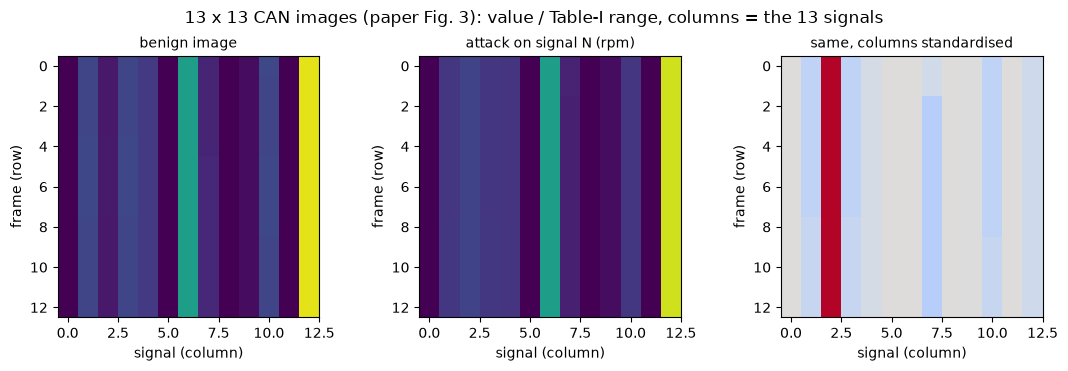

In [7]:
def make_images(Xs, y_step, af_step):
    k = len(Xs) // IMG
    img = (Xs[:k * IMG] / RANGE).reshape(k, IMG, IMG).astype(np.float32)
    lab = y_step[:k * IMG].reshape(k, IMG)
    af = af_step[:k * IMG].reshape(k, IMG)
    y = lab.max(1)
    feat = np.array([(np.bincount(a[a >= 0], minlength=13).argmax() if (a >= 0).any() else -1) for a in af])
    return img, y, feat

img_tr, y_tr, f_tr = make_images(Xtr_raw, ytr_step, aftr_step)
img_te, y_te, f_te = make_images(Xte_raw, yte_step, afte_step)

def col_stats(img, y):
    """per-column mean/std of benign training rows (used by the classical CNN / LSTM front end)"""
    rows = img[y == 0].reshape(-1, 13)
    return rows.mean(0), np.maximum(rows.std(0), 0.005)

def subsample(idx_n, n, rng):
    return np.sort(rng.choice(idx_n, n, replace=False)) if n is not None and n < idx_n else np.arange(idx_n)

rng_split = np.random.default_rng(SEED + 1)
# protocol T
a = subsample(len(img_tr), SUB_T_TRAIN, rng_split); b = subsample(len(img_te), SUB_T_TEST, rng_split)
PROT = {"T": dict(Xtr=img_tr[a], ytr=y_tr[a], Xte=img_te[b], yte=y_te[b], fte=f_te[b])}
# protocol R: pool, draw 7,000, random 80/20
img_all, y_all = np.concatenate([img_tr, img_te]), np.concatenate([y_tr, y_te])
n_r = SUB_R if SUB_R else R_N
pick = rng_split.choice(len(img_all), n_r, replace=False)
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(img_all[pick], y_all[pick], test_size=R_TEST_FRAC, random_state=SEED, stratify=y_all[pick])
PROT["R"] = dict(Xtr=Xr_tr, ytr=yr_tr, Xte=Xr_te, yte=yr_te, fte=None)
for k, P in PROT.items():
    P["mu"], P["sd"] = col_stats(P["Xtr"], P["ytr"])
    print(f"protocol {k}: train {len(P['Xtr']):5d} images ({P['ytr'].mean():.1%} attack) | test {len(P['Xte']):5d} images ({P['yte'].mean():.1%} attack)"
          f" | majority-class accuracy on test = {max(P['yte'].mean(), 1-P['yte'].mean()):.1%}")

# ---- Fig. 3: example CAN images ----
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
k_ben = int(np.where(y_tr == 0)[0][50]); k_atk = int(np.where(f_tr == 2)[0][20])
for a_, (im, tt) in zip(ax, [(img_tr[k_ben], "benign image"), (img_tr[k_atk], "attack on signal N (rpm)"), (None, "same, columns standardised")]):
    if im is None:
        mu_, sd_ = PROT["T"]["mu"], PROT["T"]["sd"]; im = np.clip((img_tr[k_atk] - mu_) / sd_, -5, 5); a_.imshow(im, cmap="coolwarm", vmin=-5, vmax=5)
    else:
        a_.imshow(im, cmap="viridis", vmin=0, vmax=0.6)
    a_.set_title(tt, fontsize=10); a_.set_xlabel("signal (column)"); a_.set_ylabel("frame (row)")
plt.suptitle("13 x 13 CAN images (paper Fig. 3): value / Table-I range, columns = the 13 signals"); plt.tight_layout(); plt.show()

Left and middle: in the raw picture only the engine-speed column changed, but by far less than the picture's dynamic range
(the signals are mostly flat at idle). Right: after standardising every column with the benign training statistics the attacked
column stands out clearly. That standardisation is the first thing the classical CNN and the LSTM do (a design choice, see the
table above); the quantum-only branch gets the raw picture, as the paper's description suggests.

## 5. Classical baselines on identical inputs

Before any quantum code, how hard is the task for ordinary classifiers? Random Forest and an RBF-SVM get the 169 standardised
pixels of each image (nothing else). Protocol T is the stricter test: they have never seen the attack constants of the test
intervals. Section 8 repeats them on the 16 binary features the quantum network will actually receive.

In [8]:
def std_flat(P, which):
    return ((P[which] - P["mu"]) / P["sd"]).reshape(len(P[which]), -1)

BASE = {}
for k, P in PROT.items():
    Atr, Ate = std_flat(P, "Xtr"), std_flat(P, "Xte")
    rf = RandomForestClassifier(300, random_state=SEED, n_jobs=-1).fit(Atr, P["ytr"])
    sv = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(Atr, P["ytr"])
    BASE[k] = {"RandomForest (169 pixels)": (rf.score(Atr, P["ytr"]), rf.score(Ate, P["yte"])),
               "SVC rbf (169 pixels)": (sv.score(Atr, P["ytr"]), sv.score(Ate, P["yte"]))}
print(pd.DataFrame({f"{k}: {m}": v for k, d in BASE.items() for m, v in d.items()}, index=["train acc", "test acc"]).T.round(4))

# how much does the (unspecified) shift size matter? Random Forest on protocol-T-style data for different shift ranges
rows = []
for lo_, hi_ in [(0.005, 0.03), (0.02, 0.10), (0.10, 0.30)]:
    SHIFT_LO_, SHIFT_HI_ = SHIFT_LO, SHIFT_HI
    SHIFT_LO, SHIFT_HI = lo_, hi_
    r_ = np.random.default_rng(SEED)
    Xa1, ya1, aa1, _ = inject_amplitude_shift(X_CLEAN[:N_TRAIN_STEPS], TRAIN_WIN, r_)
    Xa2, ya2, aa2, _ = inject_amplitude_shift(X_CLEAN[N_TRAIN_STEPS:], TEST_WIN, r_)
    SHIFT_LO, SHIFT_HI = SHIFT_LO_, SHIFT_HI_
    i1, l1, _ = make_images(Xa1, ya1, aa1); i2, l2, _ = make_images(Xa2, ya2, aa2)
    m_, s_ = col_stats(i1, l1)
    f1 = ((i1 - m_) / s_).reshape(len(i1), -1); f2 = ((i2 - m_) / s_).reshape(len(i2), -1)
    rows.append((f"{lo_:.3f}-{hi_:.2f}", RandomForestClassifier(100, random_state=SEED, n_jobs=-1).fit(f1, l1).score(f2, l2)))
print("\nRandom Forest test accuracy (protocol T) vs size of the injected shift (fraction of Table-I range):")
print(pd.DataFrame(rows, columns=["|shift| range", "RF test acc"]).round(4).to_string(index=False))

                              train acc  test acc
T: RandomForest (169 pixels)     1.0000    0.7388
T: SVC rbf (169 pixels)          0.9991    0.9128
R: RandomForest (169 pixels)     1.0000    0.9943
R: SVC rbf (169 pixels)          0.9988    0.9979



Random Forest test accuracy (protocol T) vs size of the injected shift (fraction of Table-I range):
|shift| range  RF test acc
   0.005-0.03       0.7107
   0.020-0.10       0.7388
   0.100-0.30       0.7673


## 6. The quantum circuit, gate for gate

The paper's network is the **Farhi-Neven classifier** from the TensorFlow Quantum MNIST tutorial:

* 16 **data qubits** hold a 4 x 4 binary image (bit 1 -> an `X` gate; this is the *basis encoding* of Eq. 4-5).
* 1 **read-out qubit** is prepared in |-> (`X` then `H`).
* A *layer* applies the same two-qubit gate between the read-out and **every** data qubit, each with its own trainable angle.
  Layers alternate `XX`, `ZZ`, `XX`, `ZZ`, ... (`xx1, zz1, xx2, ...` in the tutorial). Cirq's `XX**t` is
  PennyLane's `IsingXX(pi * t)`.
* A final `H` on the read-out and a Pauli-Z measurement; the expectation `<Z>` in [-1, 1] is the score (> 0 = attack).

16 gates per layer x 6 layers = **96 parameters** (hybrid, Table III); 8 layers = 128 (quantum-only).
The reference PennyLane QNode (below, drawn for 3 data qubits) is the definition of the model.

In [9]:
def reference_qnode(types, n_data=16):
    """PennyLane definition of the circuit: x = bit string, t = [L, n_data] gate exponents (Cirq convention)."""
    dev = qml.device("default.qubit", wires=n_data + 1)
    @qml.qnode(dev, interface="torch")
    def circuit(x, t):
        for i in range(n_data):
            if x[i] > 0.5: qml.PauliX(wires=i)                       # basis encoding of the 4x4 bits
        qml.PauliX(wires=n_data); qml.Hadamard(wires=n_data)         # read-out qubit in |->
        for l, ty in enumerate(types):
            for i in range(n_data):
                (qml.IsingXX if ty == "XX" else qml.IsingZZ)(np.pi * t[l][i], wires=[n_data, i])
        qml.Hadamard(wires=n_data)
        return qml.expval(qml.PauliZ(n_data))
    return circuit

demo = reference_qnode(["XX", "ZZ"], n_data=3)
print(qml.draw(demo)(torch.tensor([1., 0., 1.]), torch.zeros(2, 3)))

0: ──X────╭IsingXX(0.00)───────────────────────────────╭IsingZZ(0.00)─────────────── ···
1: ───────│──────────────╭IsingXX(0.00)────────────────│──────────────╭IsingZZ(0.00) ···
2: ──X────│──────────────│──────────────╭IsingXX(0.00)─│──────────────│───────────── ···
3: ──X──H─╰IsingXX(0.00)─╰IsingXX(0.00)─╰IsingXX(0.00)─╰IsingZZ(0.00)─╰IsingZZ(0.00) ···

0: ··· ───────────────────┤     
1: ··· ───────────────────┤     
2: ··· ─╭IsingZZ(0.00)────┤     
3: ··· ─╰IsingZZ(0.00)──H─┤  <Z>


### A fast exact simulator

Simulating 17 qubits with batch size 1 for 20 epochs is 112,000 circuit evaluations plus gradients, too slow for a notebook
with a general-purpose state-vector simulator. But this circuit has a special shape: every gate couples the read-out qubit to
**one** data qubit, and the data qubits start in basis states. If we fix the read-out qubit's "path" through the eigenbases of
the layers (`|+>,|->` for `XX` layers, `|0>,|1>` for `ZZ` layers; 2^L paths), every data qubit only experiences single-qubit
rotations, so the 16 data qubits **factorise** and the expectation value is an exact sum over pairs of paths of products of 16
small overlaps. Cost: 4^L terms instead of a 2^17-dimensional state; the result is exact (not an approximation) and
differentiable in PyTorch. The cell below implements it and then **proves** it equals the PennyLane circuit, for values and for
gradients.

In [10]:
N_DATA = 16
SQ = 1 / math.sqrt(2)
CT = torch.complex64
_X = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128)

def layer_types(n_layers):
    """xx1, zz1, xx2, zz2, ... as in the TensorFlow Quantum MNIST tutorial (one layer = 16 gates, 16 parameters)"""
    return ["XX" if l % 2 == 0 else "ZZ" for l in range(n_layers)]

class PathSumQNN:
    """Exact <Z_readout> of the 17-qubit circuit for M independent parameter sets and B bit-string inputs each."""
    def __init__(self, types):
        self.types = types; L = len(types)
        eig = {"XX": torch.tensor([[SQ, SQ], [SQ, -SQ]], dtype=torch.complex128), "ZZ": torch.eye(2, dtype=torch.complex128)}
        minus = torch.tensor([SQ, -SQ], dtype=torch.complex128)
        c = eig[types[0]].conj().T @ minus                         # amplitude of the read-out path (|-> in the first basis)
        for l in range(L - 1):
            T = eig[types[l + 1]].conj().T @ eig[types[l]]         # basis change between consecutive layers
            c = (c.reshape(-1, 2, 1) * T.T.reshape(1, 2, 2)).reshape(-1)
        E = eig[types[-1]]; K = E.conj().T @ _X @ E                # final H + Z measurement == X on the last layer's basis
        s_last = torch.arange(2 ** L) % 2
        self.cc = (c.conj()[:, None] * c[None, :] * K[s_last][:, s_last]).to(CT)     # weights of the path pairs
        self.sgn = torch.tensor([1.0, -1.0])

    def __call__(self, x, t):
        """x: [M,B,16] bits; t: [M,L,16] exponents (gate = exp(-i pi t/2 P(x)P)). returns <Z>: [M,B]"""
        M, B, _ = x.shape
        x = x.float(); t = t.float()
        d = torch.stack([1 - x, x], -1).to(CT).unsqueeze(3)        # [M,B,16,1,2]: every data qubit starts in |x_i>
        for l, ty in enumerate(self.types):
            ph = math.pi * t[:, l] / 2
            cs, sn = torch.cos(ph)[:, None, :, None, None], torch.sin(ph)[:, None, :, None, None]
            if ty == "XX": new = [cs * d - 1j * s * sn * d.flip(-1) for s in (1.0, -1.0)]       # exp(-i s a X)
            else:          new = [(cs - 1j * s * sn * self.sgn) * d for s in (1.0, -1.0)]       # exp(-i s a Z)
            d = torch.stack(new, 4).reshape(M, B, N_DATA, -1, 2)   # one extra path bit per layer
        G = torch.prod(torch.matmul(d.conj(), d.transpose(-1, -2)), 2)     # overlaps of path pairs, product over the 16 qubits
        return torch.einsum("pr,mbpr->mb", self.cc, G).real

def hinge(f, y):
    return torch.clamp(1 - y * f, min=0)

class MaskedAdam:
    """Adam (Keras defaults: beta 0.9 / 0.999, eps 1e-7) for M independent models stacked in one tensor [M, ...];
    model m only moves while active[m] is True (models with fewer steps stop early)."""
    def __init__(self, p, lr, b1=0.9, b2=0.999, eps=1e-7):
        self.p, self.lr, self.b1, self.b2, self.eps = p, lr, b1, b2, eps
        self.m, self.v, self.k = torch.zeros_like(p), torch.zeros_like(p), torch.zeros(p.shape[0])
    @torch.no_grad()
    def step(self, active):
        g = self.p.grad; sh = (-1,) + (1,) * (g.dim() - 1)
        a = active.float().view(sh); self.k += active.float(); k = self.k.clamp(min=1).view(sh)
        self.m = torch.where(a > 0, self.b1 * self.m + (1 - self.b1) * g, self.m)
        self.v = torch.where(a > 0, self.b2 * self.v + (1 - self.b2) * g * g, self.v)
        self.p -= a * self.lr * (self.m / (1 - self.b1 ** k)) / ((self.v / (1 - self.b2 ** k)).sqrt() + self.eps)
        self.p.grad = None

def train_qnn(net, X_list, y_list, n_layers, epochs, batch, lr, seeds, log_every=2000):
    """Train M independent QNNs at once (hinge loss, Adam). X_list[m]: [n_m,16] bits, y_list[m] in {0,1}.
    Parameters start uniform in [0, 2 pi) (the TFQ default). Returns parameters [M,L,16] and loss history."""
    M = len(X_list); rngs = [np.random.default_rng(s) for s in seeds]
    t = torch.tensor(np.stack([r.uniform(0, 2 * np.pi, (n_layers, N_DATA)) for r in rngs]), dtype=torch.float32, requires_grad=True)
    opt = MaskedAdam(t, lr)
    Xs = [torch.tensor(x, dtype=torch.float32) for x in X_list]; ys = [torch.tensor(2.0 * y - 1, dtype=torch.float32) for y in y_list]
    spe = [len(x) // batch for x in X_list]; total = [epochs * s for s in spe]
    orders, hist, run, cnt, t0 = [None] * M, [[] for _ in range(M)], np.zeros(M), np.zeros(M), time.time()
    for step in range(max(total)):
        active = torch.tensor([step < total[m] for m in range(M)]); idx = []
        for m in range(M):
            if step >= total[m]: idx.append(np.zeros(batch, int)); continue
            k = step % spe[m]
            if k == 0: orders[m] = rngs[m].permutation(len(Xs[m]))
            idx.append(orders[m][k * batch:(k + 1) * batch])
        xb = torch.stack([Xs[m][idx[m]] for m in range(M)]); yb = torch.stack([ys[m][idx[m]] for m in range(M)])
        uq = [torch.unique(xb[m], dim=0, return_inverse=True) for m in range(M)]      # evaluate each distinct input once
        U = max(u[0].shape[0] for u in uq)
        xu = torch.stack([torch.cat([u[0], u[0][:1].expand(U - u[0].shape[0], -1)]) for u in uq])
        fu = net(xu, t); f = torch.stack([fu[m][uq[m][1]] for m in range(M)])
        l = hinge(f, yb).mean(1)
        (l * active.float()).sum().backward(); opt.step(active)
        run += l.detach().numpy() * active.numpy(); cnt += active.numpy()
        if (step + 1) % 500 == 0 or step == max(total) - 1:
            for m in range(M):
                if cnt[m]: hist[m].append((step + 1, run[m] / cnt[m]))
            run[:] = 0; cnt[:] = 0
        if log_every and (step + 1) % log_every == 0:
            print(f"   step {step+1:>6}/{max(total)}  hinge loss " + "  ".join(f"{h[-1][1]:.3f}" for h in hist if h) + f"   ({time.time()-t0:.0f} s)", flush=True)
    return t.detach(), hist

@torch.no_grad()
def predict_qnn(net, t, X):
    """<Z> of one trained parameter set t [L,16] on bit strings X [n,16]; each distinct pattern is evaluated once."""
    uq, inv = np.unique(np.asarray(X), axis=0, return_inverse=True)
    P = 2 ** len(net.types); chunk = max(1, int(2e7 // (N_DATA * P * P))); out = []
    for i in range(0, len(uq), chunk):
        out.append(net(torch.tensor(uq[i:i + chunk], dtype=torch.float32)[None], t[None])[0])
    return torch.cat(out).numpy()[inv.reshape(-1)]

In [11]:
# ---- proof of equivalence with the PennyLane circuit: values and gradients ----
rg = np.random.default_rng(0)
print(" layers | max |value difference| over 4 random inputs | max |gradient difference| (1 input)")
for L in (2, 6, 8):
    types = layer_types(L); net_ = PathSumQNN(types); ref = reference_qnode(types)
    dv = 0.0
    for _ in range(4):
        x = rg.integers(0, 2, 16).astype(np.float32); t = rg.uniform(0, 2 * np.pi, (L, 16))
        a = ref(torch.tensor(x), torch.tensor(t)).item(); b = net_(torch.tensor(x)[None, None], torch.tensor(t, dtype=torch.float32)[None])[0, 0].item()
        dv = max(dv, abs(a - b))
    t1 = torch.tensor(t, requires_grad=True); ref(torch.tensor(x), t1).backward(); g_ref = t1.grad
    t2 = torch.tensor(t, dtype=torch.float32, requires_grad=True); net_(torch.tensor(x)[None, None], t2[None])[0, 0].backward()
    print(f"   {L}    |            {dv:.2e}                |        {(g_ref.float() - t2.grad).abs().max().item():.2e}")
print("(float32 path-sum vs float64 state vector: differences around 1e-7 mean the two are the same function)")

 layers | max |value difference| over 4 random inputs | max |gradient difference| (1 input)


   2    |            1.54e-07                |        9.24e-07


   6    |            5.76e-08                |        5.51e-07


   8    |            3.99e-08                |        2.94e-07
(float32 path-sum vs float64 state vector: differences around 1e-7 mean the two are the same function)


## 7. The quantum-only network (62.0 % in the paper)

For the quantum-only model the 13 x 13 image is **resized to 4 x 4** (bilinear, as `tf.image.resize` would do) and binarised at
0.5; then the same 17-qubit circuit with 8 layers (128 parameters) is trained with batch size 8.

With images holding `signal / range`, almost every pixel is far below 0.5 (the signals sit at 1 to 5 % of their range) and the
attack, 2 to 10 % of the range, cannot push a pixel across the threshold. The 16 input bits are therefore the **same for every
image**; a circuit that gets one constant input can only output one constant number, i.e. predict the majority class. The cell
counts the distinct inputs to make this visible before spending any quantum compute on it.

In [12]:
def resize_bits(img):
    t = torch.tensor(img)[:, None]
    return (F.interpolate(t, size=(4, 4), mode="bilinear", align_corners=False).flatten(1) > 0.5).numpy().astype(np.float32)

QO = {}
for k, P in PROT.items():
    QO[k] = dict(btr=resize_bits(P["Xtr"]), bte=resize_bits(P["Xte"]))
    n_pat = len(np.unique(np.vstack([QO[k]["btr"], QO[k]["bte"]]), axis=0))
    print(f"protocol {k}: distinct 16-bit inputs among {len(QO[k]['btr']) + len(QO[k]['bte'])} images = {n_pat};  bits set in the first image: {int(QO[k]['btr'][0].sum())}")
print(QO["T"]["btr"][0].reshape(4, 4).astype(int))

protocol T: distinct 16-bit inputs among 7322 images = 1;  bits set in the first image: 0
protocol R: distinct 16-bit inputs among 7000 images = 1;  bits set in the first image: 0
[[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


In [13]:
torch.set_num_threads(QNN_THREADS)
net_q = PathSumQNN(layer_types(QONLY_LAYERS))
t0 = time.time()
tq, hq = train_qnn(net_q, [QO[k]["btr"] for k in ("T", "R")], [PROT[k]["ytr"] for k in ("T", "R")],
                   QONLY_LAYERS, QONLY_EPOCHS, QONLY_BATCH, QONLY_LR, [SEED, SEED + 1], log_every=500)
T_QONLY = time.time() - t0
RES = {}      # RES[(model, protocol)] = dict(train=[...], test=[...], ...)
for m_, k in enumerate(("T", "R")):
    P = PROT[k]; ftr = predict_qnn(net_q, tq[m_], QO[k]["btr"]); fte = predict_qnn(net_q, tq[m_], QO[k]["bte"])
    RES[("Quantum-only", k)] = dict(train=[((ftr > 0) == P["ytr"]).mean()], test=[((fte > 0) == P["yte"]).mean()], pred_te=(fte > 0).astype(int),
                                    time=T_QONLY, params=tq[m_].numel())
    print(f"quantum-only, protocol {k}: train acc {RES[('Quantum-only', k)]['train'][0]:.4f}  test acc {RES[('Quantum-only', k)]['test'][0]:.4f}"
          f"   (output <Z> = {fte[0]:+.3f} for every image)  [{RES[('Quantum-only', k)]['params']} parameters]")
print(f"training time {T_QONLY:.0f} s")

   step    500/2100  hinge loss 0.891  0.847   (57 s)


   step   1000/2100  hinge loss 0.888  0.813   (101 s)


   step   1500/2100  hinge loss 0.874  0.828   (151 s)


   step   2000/2100  hinge loss 0.875  0.830   (211 s)


quantum-only, protocol T: train acc 0.5636  test acc 0.6254   (output <Z> = -1.000 for every image)  [128 parameters]
quantum-only, protocol R: train acc 0.5873  test acc 0.5871   (output <Z> = -0.999 for every image)  [128 parameters]
training time 222 s


## 8. The hybrid network: classical CNN + 17-qubit quantum network

The CNN turns the (standardised) 13 x 13 image into a 4 x 4 map in (0, 1). We **pre-train it with a small linear head** (so
that the 16 numbers carry the attack information), freeze it, **binarise at 0.5**, and let the quantum network (6 layers, 96
parameters, batch size 1) classify the 16 bits. Everything is trained on the training images only. The cell trains one CNN per
protocol and seed.

In [14]:
torch.set_num_threads(NN_THREADS)
class CanCNN(nn.Module):
    """13x13 CAN image -> 4x4 map (paper Fig. 2). Front end: column standardisation with benign-training statistics."""
    def __init__(self, mu, sd):
        super().__init__()
        self.register_buffer("mu", torch.tensor(mu, dtype=torch.float32)); self.register_buffer("sd", torch.tensor(sd, dtype=torch.float32))
        self.f = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
                               nn.Conv2d(32, 1, 4, stride=3))                # 13 -> 13 -> 13 -> 4
        self.head = nn.Linear(16, 1)                                         # used only to pre-train the feature map
    def feat(self, x): return torch.sigmoid(self.f(((x - self.mu) / self.sd).unsqueeze(1))).flatten(1)
    def forward(self, x): return self.head(self.feat(x)).squeeze(1)

def train_cnn(P, seed, epochs):
    torch.manual_seed(seed)
    m = CanCNN(P["mu"], P["sd"]); opt = torch.optim.Adam(m.parameters(), 1e-3)
    X, y = torch.tensor(P["Xtr"]), torch.tensor(P["ytr"], dtype=torch.float32); g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 32):
            b = perm[i:i + 32]; loss = F.binary_cross_entropy_with_logits(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

CNNS, BITS = {}, {}
t0 = time.time()
for k, P in PROT.items():
    for s in HYB_SEEDS:
        m = train_cnn(P, SEED + s, CNN_EPOCHS)
        with torch.no_grad():
            btr = (m.feat(torch.tensor(P["Xtr"])) > 0.5).numpy().astype(np.float32); bte = (m.feat(torch.tensor(P["Xte"])) > 0.5).numpy().astype(np.float32)
            head_tr = ((m(torch.tensor(P["Xtr"])) > 0).numpy() == P["ytr"]).mean(); head_te = ((m(torch.tensor(P["Xte"])) > 0).numpy() == P["yte"]).mean()
        CNNS[(k, s)], BITS[(k, s)] = m, dict(btr=btr, bte=bte, head=(head_tr, head_te))
        print(f"protocol {k} seed {s}: CNN+linear head (classical only) train {head_tr:.4f} test {head_te:.4f} | "
              f"distinct 16-bit codes in train: {len(np.unique(btr, axis=0))}")
print(f"CNN parameters (feature map + head): {sum(p.numel() for p in CNNS[('T', HYB_SEEDS[0])].parameters())},  {time.time()-t0:.0f} s")

protocol T seed 0: CNN+linear head (classical only) train 0.9248 test 0.7141 | distinct 16-bit codes in train: 219


protocol T seed 1: CNN+linear head (classical only) train 0.9647 test 0.6099 | distinct 16-bit codes in train: 146


protocol T seed 2: CNN+linear head (classical only) train 0.9285 test 0.8112 | distinct 16-bit codes in train: 172


protocol R seed 0: CNN+linear head (classical only) train 0.9361 test 0.9364 | distinct 16-bit codes in train: 121


protocol R seed 1: CNN+linear head (classical only) train 0.9343 test 0.9336 | distinct 16-bit codes in train: 65


protocol R seed 2: CNN+linear head (classical only) train 0.8948 test 0.9021 | distinct 16-bit codes in train: 203
CNN parameters (feature map + head): 5330,  269 s


In [15]:
# ---- classical models on the SAME 16 bits the quantum network receives ----
for k, P in PROT.items():
    b = BITS[(k, HYB_SEEDS[0])]
    rf = RandomForestClassifier(300, random_state=SEED, n_jobs=-1).fit(b["btr"], P["ytr"]); sv = SVC(kernel="rbf", random_state=SEED).fit(b["btr"], P["ytr"])
    BASE[k]["RandomForest (CNN 16 bits)"] = (rf.score(b["btr"], P["ytr"]), rf.score(b["bte"], P["yte"]))
    BASE[k]["SVC rbf (CNN 16 bits)"] = (sv.score(b["btr"], P["ytr"]), sv.score(b["bte"], P["yte"]))
    BASE[k]["CNN + linear head (no quantum)"] = b["head"]
print(pd.DataFrame({f"{k}: {m}": v for k, d in BASE.items() for m, v in d.items()}, index=["train acc", "test acc"]).T.round(4))

                                   train acc  test acc
T: RandomForest (169 pixels)          1.0000    0.7388
T: SVC rbf (169 pixels)               0.9991    0.9128
T: RandomForest (CNN 16 bits)         0.9811    0.8123
T: SVC rbf (CNN 16 bits)              0.9798    0.8389
T: CNN + linear head (no quantum)     0.9248    0.7141
R: RandomForest (169 pixels)          1.0000    0.9943
R: SVC rbf (169 pixels)               0.9988    0.9979
R: RandomForest (CNN 16 bits)         0.9746    0.9643
R: SVC rbf (CNN 16 bits)              0.9743    0.9657
R: CNN + linear head (no quantum)     0.9361    0.9364


In [16]:
# ---- train all hybrid quantum networks at once: one independent model per (protocol, seed) ----
torch.set_num_threads(QNN_THREADS)
net_h = PathSumQNN(layer_types(HYB_LAYERS))
keys = [(k, s) for k in ("T", "R") for s in HYB_SEEDS]
print(f"training {len(keys)} hybrid quantum networks ({HYB_EPOCHS} epochs, batch {HYB_BATCH}, lr {HYB_LR}); "
      f"steps: {[HYB_EPOCHS * (len(PROT[k]['ytr']) // HYB_BATCH) for k, s in keys]}")
t0 = time.time()
th, hh = train_qnn(net_h, [BITS[key]["btr"] for key in keys], [PROT[k]["ytr"] for k, s in keys], HYB_LAYERS, HYB_EPOCHS, HYB_BATCH, HYB_LR,
                   [SEED + 100 * (1 if k == "T" else 2) + s for k, s in keys], log_every=10000)
T_HYB = time.time() - t0
print(f"quantum training time: {T_HYB:.0f} s  ({T_HYB/60:.1f} min)")
for k in ("T", "R"):
    RES[("Hybrid", k)] = dict(train=[], test=[], pred_te=[], time=T_HYB, params=th[0].numel(), hist=[])
for i, (k, s) in enumerate(keys):
    P, b = PROT[k], BITS[(k, s)]
    ftr, fte = predict_qnn(net_h, th[i], b["btr"]), predict_qnn(net_h, th[i], b["bte"])
    r = RES[("Hybrid", k)]; r["train"].append(((ftr > 0) == P["ytr"]).mean()); r["test"].append(((fte > 0) == P["yte"]).mean())
    r["pred_te"].append((fte > 0).astype(int)); r["hist"].append(hh[i])
    print(f"hybrid protocol {k} seed {s}: train acc {r['train'][-1]:.4f}  test acc {r['test'][-1]:.4f}")

training 6 hybrid quantum networks (20 epochs, batch 1, lr 0.001); steps: [92300, 92300, 92300, 112000, 112000, 112000]


   step  10000/112000  hinge loss 0.330  0.019  0.215  0.273  0.076  0.195   (404 s)


   step  20000/112000  hinge loss 0.260  0.011  0.238  0.306  0.084  0.257   (886 s)


   step  30000/112000  hinge loss 0.277  0.013  0.224  0.249  0.070  0.234   (1359 s)


   step  40000/112000  hinge loss 0.283  0.021  0.248  0.291  0.097  0.285   (1823 s)


...

hybrid protocol T seed 1: train acc 0.9933  test acc 0.7144


hybrid protocol T seed 2: train acc 0.8817  test acc 0.7928


hybrid protocol R seed 0: train acc 0.8777  test acc 0.8507


hybrid protocol R seed 1: train acc 0.9682  test acc 0.9650


hybrid protocol R seed 2: train acc 0.8823  test acc 0.8893


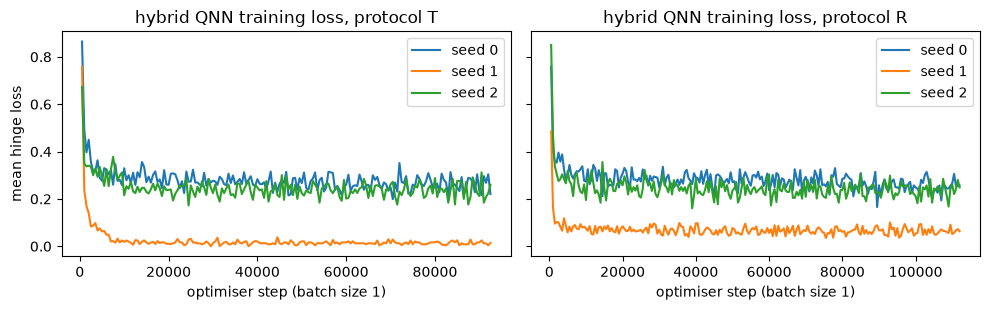

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a_, k in zip(ax, ("T", "R")):
    for i, h in enumerate(RES[("Hybrid", k)]["hist"]):
        a_.plot([x for x, _ in h], [y for _, y in h], label=f"seed {HYB_SEEDS[i]}")
    a_.set_title(f"hybrid QNN training loss, protocol {k}"); a_.set_xlabel("optimiser step (batch size 1)"); a_.legend()
ax[0].set_ylabel("mean hinge loss"); plt.tight_layout(); plt.show()

## 9. The LSTM baseline

The paper compares with the LSTM of Khan et al. (2020), "same model architecture", 3 layers, 1,090,049 parameters, batch size
32, 100 epochs. The layer sizes are not given, so we use three stacked LSTM layers (300, 256, 100 units) + one output unit,
which lands within 20 parameters of the paper's count. The 13 rows of an image are the 13 time steps, the 13 columns the
features (after the same column standardisation).

In [18]:
torch.set_num_threads(NN_THREADS)
def keras_lstm_params(i, u): return 4 * (u * (i + u) + u)
class LSTMNet(nn.Module):
    def __init__(self, mu, sd):
        super().__init__()
        self.register_buffer("mu", torch.tensor(mu, dtype=torch.float32)); self.register_buffer("sd", torch.tensor(sd, dtype=torch.float32))
        self.l1, self.l2, self.l3 = nn.LSTM(13, 300, batch_first=True), nn.LSTM(300, 256, batch_first=True), nn.LSTM(256, 100, batch_first=True)
        self.out = nn.Linear(100, 1)
    def forward(self, x):
        h, _ = self.l1((x - self.mu) / self.sd); h, _ = self.l2(h); h, _ = self.l3(h)
        return self.out(h[:, -1]).squeeze(1)
n_keras = keras_lstm_params(13, 300) + keras_lstm_params(300, 256) + keras_lstm_params(256, 100) + 101
print("LSTM parameters (Keras counting):", n_keras, "| paper Table III: 1,090,049 | PyTorch counting (two bias vectors):",
      sum(p.numel() for p in LSTMNet(PROT['T']['mu'], PROT['T']['sd']).parameters()))

def train_lstm(P, seed, epochs):
    torch.manual_seed(seed); m = LSTMNet(P["mu"], P["sd"]); opt = torch.optim.Adam(m.parameters(), 1e-3)
    X, y = torch.tensor(P["Xtr"]), torch.tensor(P["ytr"], dtype=torch.float32); Xe = torch.tensor(P["Xte"]); g = torch.Generator().manual_seed(seed)
    curve = []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X) - 31, 32):                                   # batch size 32
            b = perm[i:i + 32]; loss = F.binary_cross_entropy_with_logits(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad(): curve.append(((m(Xe) > 0).numpy() == P["yte"]).mean())     # monitoring only; never used for selection
    with torch.no_grad(): ptr, pte = (m(X) > 0).numpy().astype(int), (m(Xe) > 0).numpy().astype(int)
    return ptr, pte, curve

t0 = time.time()
for k, P in PROT.items():
    RES[("LSTM", k)] = dict(train=[], test=[], pred_te=[], curve=[], params=n_keras)
    for s in LSTM_SEEDS:
        ptr, pte, curve = train_lstm(P, SEED + s, LSTM_EPOCHS)
        r = RES[("LSTM", k)]; r["train"].append((ptr == P["ytr"]).mean()); r["test"].append((pte == P["yte"]).mean()); r["pred_te"].append(pte); r["curve"].append(curve)
        print(f"LSTM protocol {k} seed {s}: train acc {r['train'][-1]:.4f}  test acc {r['test'][-1]:.4f}  ({time.time()-t0:.0f} s)", flush=True)
    RES[("LSTM", k)]["time"] = time.time() - t0
T_LSTM = time.time() - t0

LSTM parameters (Keras counting): 1090069 | paper Table III: 1,090,049 | PyTorch counting (two bias vectors): 1092693


LSTM protocol T seed 0: train acc 0.9998  test acc 0.8260  (1184 s)


LSTM protocol R seed 0: train acc 0.9996  test acc 0.9993  (2271 s)


## 10. Results: the paper's Fig. 4, side by side

Accuracies (mean over seeds where several were run; the hybrid network used 3 seeds in the full run) next to the paper's bars.
Protocol **T** is the temporal split of Table II (unseen attack intervals), **R** the random 80 / 20 split of the text.

,paper train,paper test,notebook T train,notebook T test,notebook R train,notebook R test
model,,,,,,
Hybrid,98.75,93.97,91.5 +- 5.6,76.4 +- 3.5,90.9 +- 4.2,90.2 +- 4.7
Quantum-only,85.71,62.03,56.4,62.5,58.7,58.7
LSTM,99.96,87.80,100.0,82.6,100.0,99.9


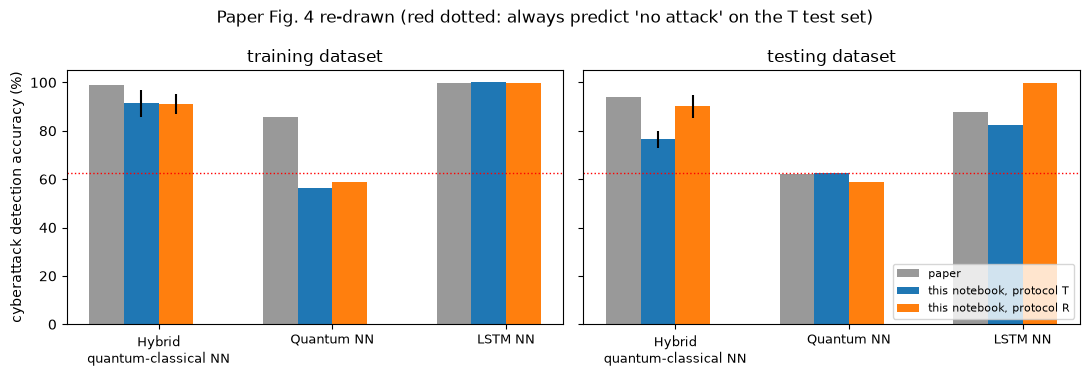

In [19]:
PAPER = {("Hybrid", "train"): 98.75, ("Hybrid", "test"): 93.97, ("Quantum-only", "train"): 85.71, ("Quantum-only", "test"): 62.03,
         ("LSTM", "train"): 99.96, ("LSTM", "test"): 87.80}
def ms(v): return 100 * np.mean(v), 100 * (np.std(v) if len(v) > 1 else 0.0)
rows = []
for mdl in ("Hybrid", "Quantum-only", "LSTM"):
    row = {"model": mdl, "paper train": PAPER[(mdl, "train")], "paper test": PAPER[(mdl, "test")]}
    for k in ("T", "R"):
        for sp in ("train", "test"):
            m_, s_ = ms(RES[(mdl, k)][sp]); row[f"notebook {k} {sp}"] = f"{m_:.1f} +- {s_:.1f}" if s_ else f"{m_:.1f}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels = ["Hybrid\nquantum-classical NN", "Quantum NN", "LSTM NN"]; mdls = ["Hybrid", "Quantum-only", "LSTM"]; xs = np.arange(3); w = 0.2
for a_, sp in zip(ax, ("train", "test")):
    a_.bar(xs - 1.5 * w, [PAPER[(m, sp)] for m in mdls], w, label="paper", color="0.6")
    a_.bar(xs - 0.5 * w, [ms(RES[(m, "T")][sp])[0] for m in mdls], w, yerr=[ms(RES[(m, "T")][sp])[1] for m in mdls], label="this notebook, protocol T")
    a_.bar(xs + 0.5 * w, [ms(RES[(m, "R")][sp])[0] for m in mdls], w, yerr=[ms(RES[(m, "R")][sp])[1] for m in mdls], label="this notebook, protocol R")
    a_.set_xticks(xs); a_.set_xticklabels(labels, fontsize=9); a_.set_title(f"{sp}ing dataset"); a_.set_ylim(0, 105)
    a_.axhline(100 * max(PROT["T"]["yte"].mean(), 1 - PROT["T"]["yte"].mean()), color="r", ls=":", lw=1)
ax[0].set_ylabel("cyberattack detection accuracy (%)"); ax[1].legend(loc="lower right", fontsize=8)
plt.suptitle("Paper Fig. 4 re-drawn (red dotted: always predict 'no attack' on the T test set)"); plt.tight_layout(); plt.show()

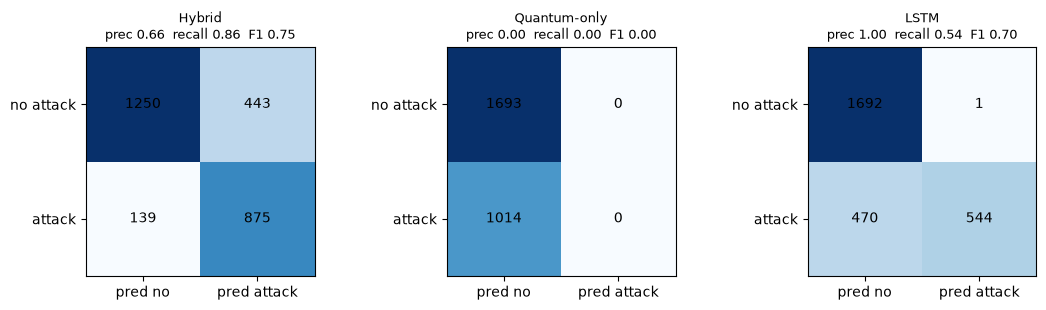

share of attack images detected, by attacked signal (protocol T, test set):
attacked signal  images  hybrid recall  LSTM recall
   TQI_COR_STAT      78          0.423        0.000
       TQI_ACOR      78          1.000        0.000
              N      78          1.000        1.000
      TQI-EMS11      78          0.987        0.000
           TQFR      78          0.987        0.974
             VS      78          1.000        0.000
      BRAKE_ACT      78          0.949        1.000
            TPS      78          0.936        1.000
      PV_AV_CAN      78          0.949        1.000
        TQI_MIN      78          0.987        1.000
      TQI-EMS16      78          0.962        0.000
     TQI_TARGET      78          0.974        0.000
        TQI_MAX      78          0.064        1.000


In [20]:
# confusion matrices (attack = positive class), protocol T test set, first seed
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a_, mdl in zip(ax, ("Hybrid", "Quantum-only", "LSTM")):
    pr = RES[(mdl, "T")]["pred_te"]; pr = pr[0] if isinstance(pr, list) else pr
    cm = confusion_matrix(PROT["T"]["yte"], pr, labels=[0, 1]); a_.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a_.text(j, i, cm[i, j], ha="center", va="center", color="k")
    p_, r_, f_, _ = precision_recall_fscore_support(PROT["T"]["yte"], pr, average="binary", zero_division=0)
    a_.set_title(f"{mdl}\nprec {p_:.2f}  recall {r_:.2f}  F1 {f_:.2f}", fontsize=9); a_.set_xticks([0, 1]); a_.set_yticks([0, 1])
    a_.set_xticklabels(["pred no", "pred attack"]); a_.set_yticklabels(["no attack", "attack"])
plt.tight_layout(); plt.show()

# which attacked signal is hard?  (protocol T, hybrid seed 0 and LSTM, test images of each attacked signal)
fte = PROT["T"]["fte"]
if fte is not None:
    rows = []
    for j in range(13):
        sel = fte == j
        if sel.sum():
            rows.append((NAMES[j], int(sel.sum()), (RES[("Hybrid", "T")]["pred_te"][0][sel] == 1).mean(), (RES[("LSTM", "T")]["pred_te"][0][sel] == 1).mean()))
    print("share of attack images detected, by attacked signal (protocol T, test set):")
    print(pd.DataFrame(rows, columns=["attacked signal", "images", "hybrid recall", "LSTM recall"]).round(3).to_string(index=False))

## 11. Side-by-side verdicts

For every claim the notebook can test we print the paper's value, ours (both protocols) and a verdict: **reproduced** if within
2 accuracy points, **not reached** / **exceeded** otherwise with the gap, **cannot be checked** when no number is comparable.

In [21]:
def verdict(paper, nb):
    d = nb - paper
    return "reproduced" if abs(d) <= 2 else (f"exceeded ({d:+.1f})" if d > 0 else f"not reached ({d:+.1f})")
rows = []
for mdl, nm in (("Hybrid", "hybrid"), ("Quantum-only", "quantum-only"), ("LSTM", "LSTM")):
    for sp in ("train", "test"):
        pv = PAPER[(mdl, sp)]; vt, vr = ms(RES[(mdl, "T")][sp])[0], ms(RES[(mdl, "R")][sp])[0]
        rows.append((f"{nm} {sp} accuracy (Fig. 4)", f"{pv:.1f}", f"{vt:.1f}", verdict(pv, vt), f"{vr:.1f}", verdict(pv, vr)))
mt = {m: ms(RES[(m, "T")]["test"])[0] for m in ("Hybrid", "Quantum-only", "LSTM")}; mr = {m: ms(RES[(m, "R")]["test"])[0] for m in mt}
rows.append(("ordering on test data: hybrid > LSTM > quantum-only", "93.9 > 87.8 > 62.0",
             " > ".join(f"{mt[m]:.1f}" for m in ("Hybrid", "LSTM", "Quantum-only")), "reproduced" if mt["Hybrid"] > mt["LSTM"] > mt["Quantum-only"] else "not reproduced",
             " > ".join(f"{mr[m]:.1f}" for m in ("Hybrid", "LSTM", "Quantum-only")), "reproduced" if mr["Hybrid"] > mr["LSTM"] > mr["Quantum-only"] else "not reproduced"))
rows.append(("hybrid beats its own classical part (CNN + linear head, no quantum circuit) on test", "not claimed",
             f"{mt['Hybrid']:.1f} vs {100*BASE['T']['CNN + linear head (no quantum)'][1]:.1f}", "cannot be checked (not in paper)",
             f"{mr['Hybrid']:.1f} vs {100*BASE['R']['CNN + linear head (no quantum)'][1]:.1f}", "cannot be checked (not in paper)"))
rows.append(("Table II label counts (train 26000/34000, test 13000/22200)", "26000/34000, 13000/22200", "same", "reproduced (by construction)", "same", "reproduced (by construction)"))
rows.append(("Table III: hybrid quantum parameters", "96", str(RES[("Hybrid", "T")]["params"]), "reproduced" if RES[("Hybrid", "T")]["params"] == 96 else "differs", "", ""))
rows.append(("Table III: quantum-only parameters", "128", str(RES[("Quantum-only", "T")]["params"]), "reproduced" if RES[("Quantum-only", "T")]["params"] == 128 else "differs", "", ""))
rows.append(("Table III: LSTM parameters", "1,090,049", f"{n_keras:,}", "close (+20, layer sizes not given)", "", ""))
rows.append(("Table II/Section III: 95,200 time steps of 0.1 s each", "0.1 s per step", "about 10 ms per step (0x316 arrival rate)", "cannot be reconciled", "", ""))
rows.append(("Cloud-supported / latency / delay requirements", "claimed qualitatively (Fig. 1)", "-", "cannot be checked (no experiment in paper)", "", ""))
final = pd.DataFrame(rows, columns=["claim", "paper", "notebook T", "verdict T", "notebook R", "verdict R"])
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 250)
display(final)
print(f"\ntiming: quantum-only {RES[('Quantum-only','T')]['time']:.0f} s | hybrid QNNs (all {len(keys)} at once) {RES[('Hybrid','T')]['time']:.0f} s | LSTM {T_LSTM:.0f} s")

,claim,paper,notebook T,verdict T,notebook R,verdict R
0,hybrid train accuracy (Fig. 4),98.8,91.5,not reached (-7.3),90.9,not reached (-7.8)
1,hybrid test accuracy (Fig. 4),94.0,76.4,not reached (-17.6),90.2,not reached (-3.8)
2,quantum-only train accuracy (Fig. 4),85.7,56.4,not reached (-29.4),58.7,not reached (-27.0)
3,quantum-only test accuracy (Fig. 4),62.0,62.5,reproduced,58.7,not reached (-3.3)
4,LSTM train accuracy (Fig. 4),100.0,100.0,reproduced,100.0,reproduced
5,LSTM test accuracy (Fig. 4),87.8,82.6,not reached (-5.2),99.9,exceeded (+12.1)
6,ordering on test data: hybrid > LSTM > quantum-only,93.9 > 87.8 > 62.0,76.4 > 82.6 > 62.5,not reproduced,90.2 > 99.9 > 58.7,not reproduced
7,"hybrid beats its own classical part (CNN + linear head, no quantum circuit) ...",not claimed,76.4 vs 71.4,cannot be checked (not in paper),90.2 vs 93.6,cannot be checked (not in paper)
8,"Table II label counts (train 26000/34000, test 13000/22200)","26000/34000, 13000/22200",same,reproduced (by construction),same,reproduced (by construction)
9,Table III: hybrid quantum parameters,96,96,reproduced,,



timing: quantum-only 222 s | hybrid QNNs (all 6 at once) 5900 s | LSTM 2271 s


## 12. Reading the paper critically

**What the numbers say (full run, see sections 5 to 11).** Under the temporal split of Table II (protocol T) the hybrid network
reaches 91.5 +- 5.6 % on its training images and **76.4 +- 3.5 %** on unseen attack intervals (three seeds: 78.5, 71.4, 79.3 %), against
98.7 % / 93.9 % in the paper. Under the random 80 / 20 split (protocol R) it reaches 90.2 +- 4.7 % on test images (85.1, 96.5, 88.9 %).
The LSTM fits its training data perfectly (100 %) but gets 82.6 % on protocol T and 99.9 % on protocol R, so **the paper's ordering
"hybrid > LSTM > quantum-only" is not reproduced under either reading of the split**: the LSTM beats the hybrid network in both.
Only the LSTM training accuracy (100 %) and the quantum-only test accuracy under T (62.5 % vs 62.0 %) land within the 2-point tolerance.

**1. The quantum-only result is a majority-class result.** With images that hold `signal / range`, the resized and binarised 4 x 4
input is the all-zero pattern for **every** image (section 7 counts one distinct input among 7,322 images), so the circuit outputs one
constant and predicts "no attack" for everything. Its T test accuracy (62.5 %) is exactly the share of attack-free test images, within
half a point of the paper's 62.0 % (the share of non-attack time steps in Table II's test part is 63.1 %). The paper's 85.7 % *training* accuracy cannot come from a constant input (the best a
constant predictor can do on our training images is 56.4 %), so the paper's quantum-only branch must have seen a differently scaled
picture. "Quantum NN alone is worse than hybrid" is therefore a statement about a particular, degenerate input pipeline, not about
quantum networks.

**2. No evidence that the quantum circuit does the work.** The hybrid network is a classical CNN that squeezes the image into 16
bits, followed by a 96-parameter circuit that classifies those bits. On the **same 16 bits** (seed 0, protocol T) a Random Forest gets
81.2 % and an RBF-SVM 83.9 % versus 78.5 % for the quantum circuit; on protocol R 96.4 % / 96.6 % versus 85.1 %. The circuit is
better than the CNN's own linear head on the soft 16-number map (seed-0 head: 71.4 %; the three seeds average 71.2 %, the head column of
the table is seed 0 only), so it is a usable classifier, but any classical learner on the same bits is at least as good. More
striking: an RBF-SVM directly on the 169 standardised pixels reaches **91.3 %** on protocol T and 99.8 % on R, better than every neural model
here and, on R, close to perfect. The task, as we could reconstruct it, does not need a quantum network.

**3. Protocol T tests generalisation to unseen attack constants, and models fail in revealing ways.** Each signal is attacked once in
training and once in testing *with a different random constant*. The per-signal table in section 10 shows the LSTM detects every
signal whose test shift has the **same sign** as its training shift (5 of 5) but misses 6 of the 8 signals whose sign flipped
(0 % recall on TQI_COR_STAT, TQI_ACOR, TQI-EMS11, VS, TQI-EMS16, TQI_TARGET; TQFR and TPS flipped sign and were still found). It
has largely learned "this column moved in that direction". The hybrid network is far more even (94 to 100 % on 11 signals) but nearly
blind to TQI_MAX (6 %) and weak on TQI_COR_STAT (42 %). The size of the shift is not the explanation: the Random Forest test accuracy only moves
from 71 % to 77 % when the shift range is multiplied by more than 10 (section 5).

**4. The data are an idling car.** Six of the 13 signals are constant and the others vary by about one percent of their range, so
"the trend stays the same" (the paper's argument for why this attack is hard) has little to apply to. With a parked car even a small
shift is a clear step; the difficulty in protocol T comes from the unseen constants, not from the signals' dynamics.

**5. Details the paper does not allow us to pin down.** The shift magnitude, how the CNN is trained (binarising at 0.5 has no
gradient), the CNN and LSTM layer sizes, the learning rates, the image labelling rule, how the 95,200 time steps "of 0.1 s" were made
(the log gives about 10 ms per 0x316 message), whether N = 7,000 or the 4,615 / 2,707 images of Table II were used (the text and the
table disagree), and "7 layers" vs 128 parameters for the quantum-only model (we use 8 layers). Each is a `# CHOICE:` here and any of
them can move the numbers by more than the gap we are trying to explain. The single run per model in the paper cannot show seed
variance; our three hybrid seeds already span 8 points on protocol T.

**6. What was not tested.** The "cloud-supported" part (Fig. 1: latency, data upload and download delay, running on a quantum
cloud service) has no experiment in the paper and none here; all quantum computations are noise-free simulations, so nothing is said
about real devices (17 qubits with 96 two-qubit gates per sample would be hard on current hardware). The LSTM was trained for 20
instead of 100 epochs (its training accuracy was already 100 %), the quantum-only network for 3 instead of 50 epochs (its input is
constant), both documented above.

**Status.** Partially reproduced: the data pipeline, Table II counts, parameter counts and the quantum-only collapse are reproduced;
the headline hybrid accuracies and the hybrid > LSTM ordering are not.

## 13. Exercises

1. **Shift size.** Change `SHIFT_LO, SHIFT_HI` to `(0.10, 0.30)` and to `(0.005, 0.03)` and re-run sections 3-11. How do the hybrid, the LSTM and the Random Forest react? At what size does the quantum-only input stop being constant?
2. **Image scaling.** Replace `value / Table-I range` by a min-max scaling fitted on the *benign training rows of each column* before the resize in section 7. Does the quantum-only network now learn something? Does it beat the 62 % "always no attack" line?
3. **Joint training.** Binarising the CNN output blocks gradients. Replace the hard threshold by a straight-through estimator: forward with the bit, backward through the sigmoid. The initial qubit state `(1-x, x)` in `PathSumQNN` is already differentiable in `x`. Does end-to-end training close the gap between protocol T and protocol R?
4. **Deeper circuit.** Run the hybrid with 2, 4, 6 and 8 layers. The path-sum cost grows as 4^L; plot accuracy against parameter count. Is 96 parameters enough, or too many for 16 bits?
5. **Unlabelled intervals.** Re-draw the attack with the constant fixed to **+** in training and **-** in testing (or vice versa). Which models notice a sign flip? What does that say about "the trend stays the same" as a design argument?